In [622]:
# 导入后续需要的库函数
import pandas as pd
import numpy as ny
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from pandas.plotting import parallel_coordinates
from matplotlib.cm import tab10
import seaborn as sns
import matplotlib.dates as mdates

#准备工作，防止因字体、负数而出错
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

#分别读取和命名四份数据
df_index=pd.read_csv(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\日-合并_按年份切片.csv", encoding='utf-8')
df_feature=pd.read_csv(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\features2.csv", encoding='utf-8')
df_lifecircle=pd.read_csv(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\lifecycle_start-end.csv", encoding='utf-8')
df_type=pd.read_csv(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\热词聚类结果.csv")

#确保日期列是datetime类型
df_index['日期'] = pd.to_datetime(df_index['日期'])
df_lifecircle['start_date'] = pd.to_datetime(df_lifecircle['start_date'])
df_lifecircle['end_date'] = pd.to_datetime(df_lifecircle['end_date'])

#标准化数据,并转为二维表格df_feature_scaled
# 1）选择列，标准化数据
columns=['peak','mean','lifecycle_days','rise_speed','skewness','kurtosis','rise_half_life','fall_half_life','trend_ratio']
scaled=StandardScaler().fit_transform(df_feature[columns]).copy()

# 2）将标准化后的数据转为二维表格,并加上列名、对应的关键词和聚类结果
df_feature_scaled=pd.DataFrame(scaled, columns=columns)
df_feature_scaled['keyword'] = df_feature['keyword'].values
df_feature_scaled['cluster']=df_type['kmeans_cluster'].values

# 3）为了后面画图图例显示方便，把类型名称替换进表中的123类别
# 注：map()函数由AI学习而来
rename={
    1:"长期流行型",2:"短期爆火型",3:"平稳发酵型"
}
df_feature_scaled['cluster']=df_feature_scaled['cluster'].map(rename)

## （一）聚类部分可视化

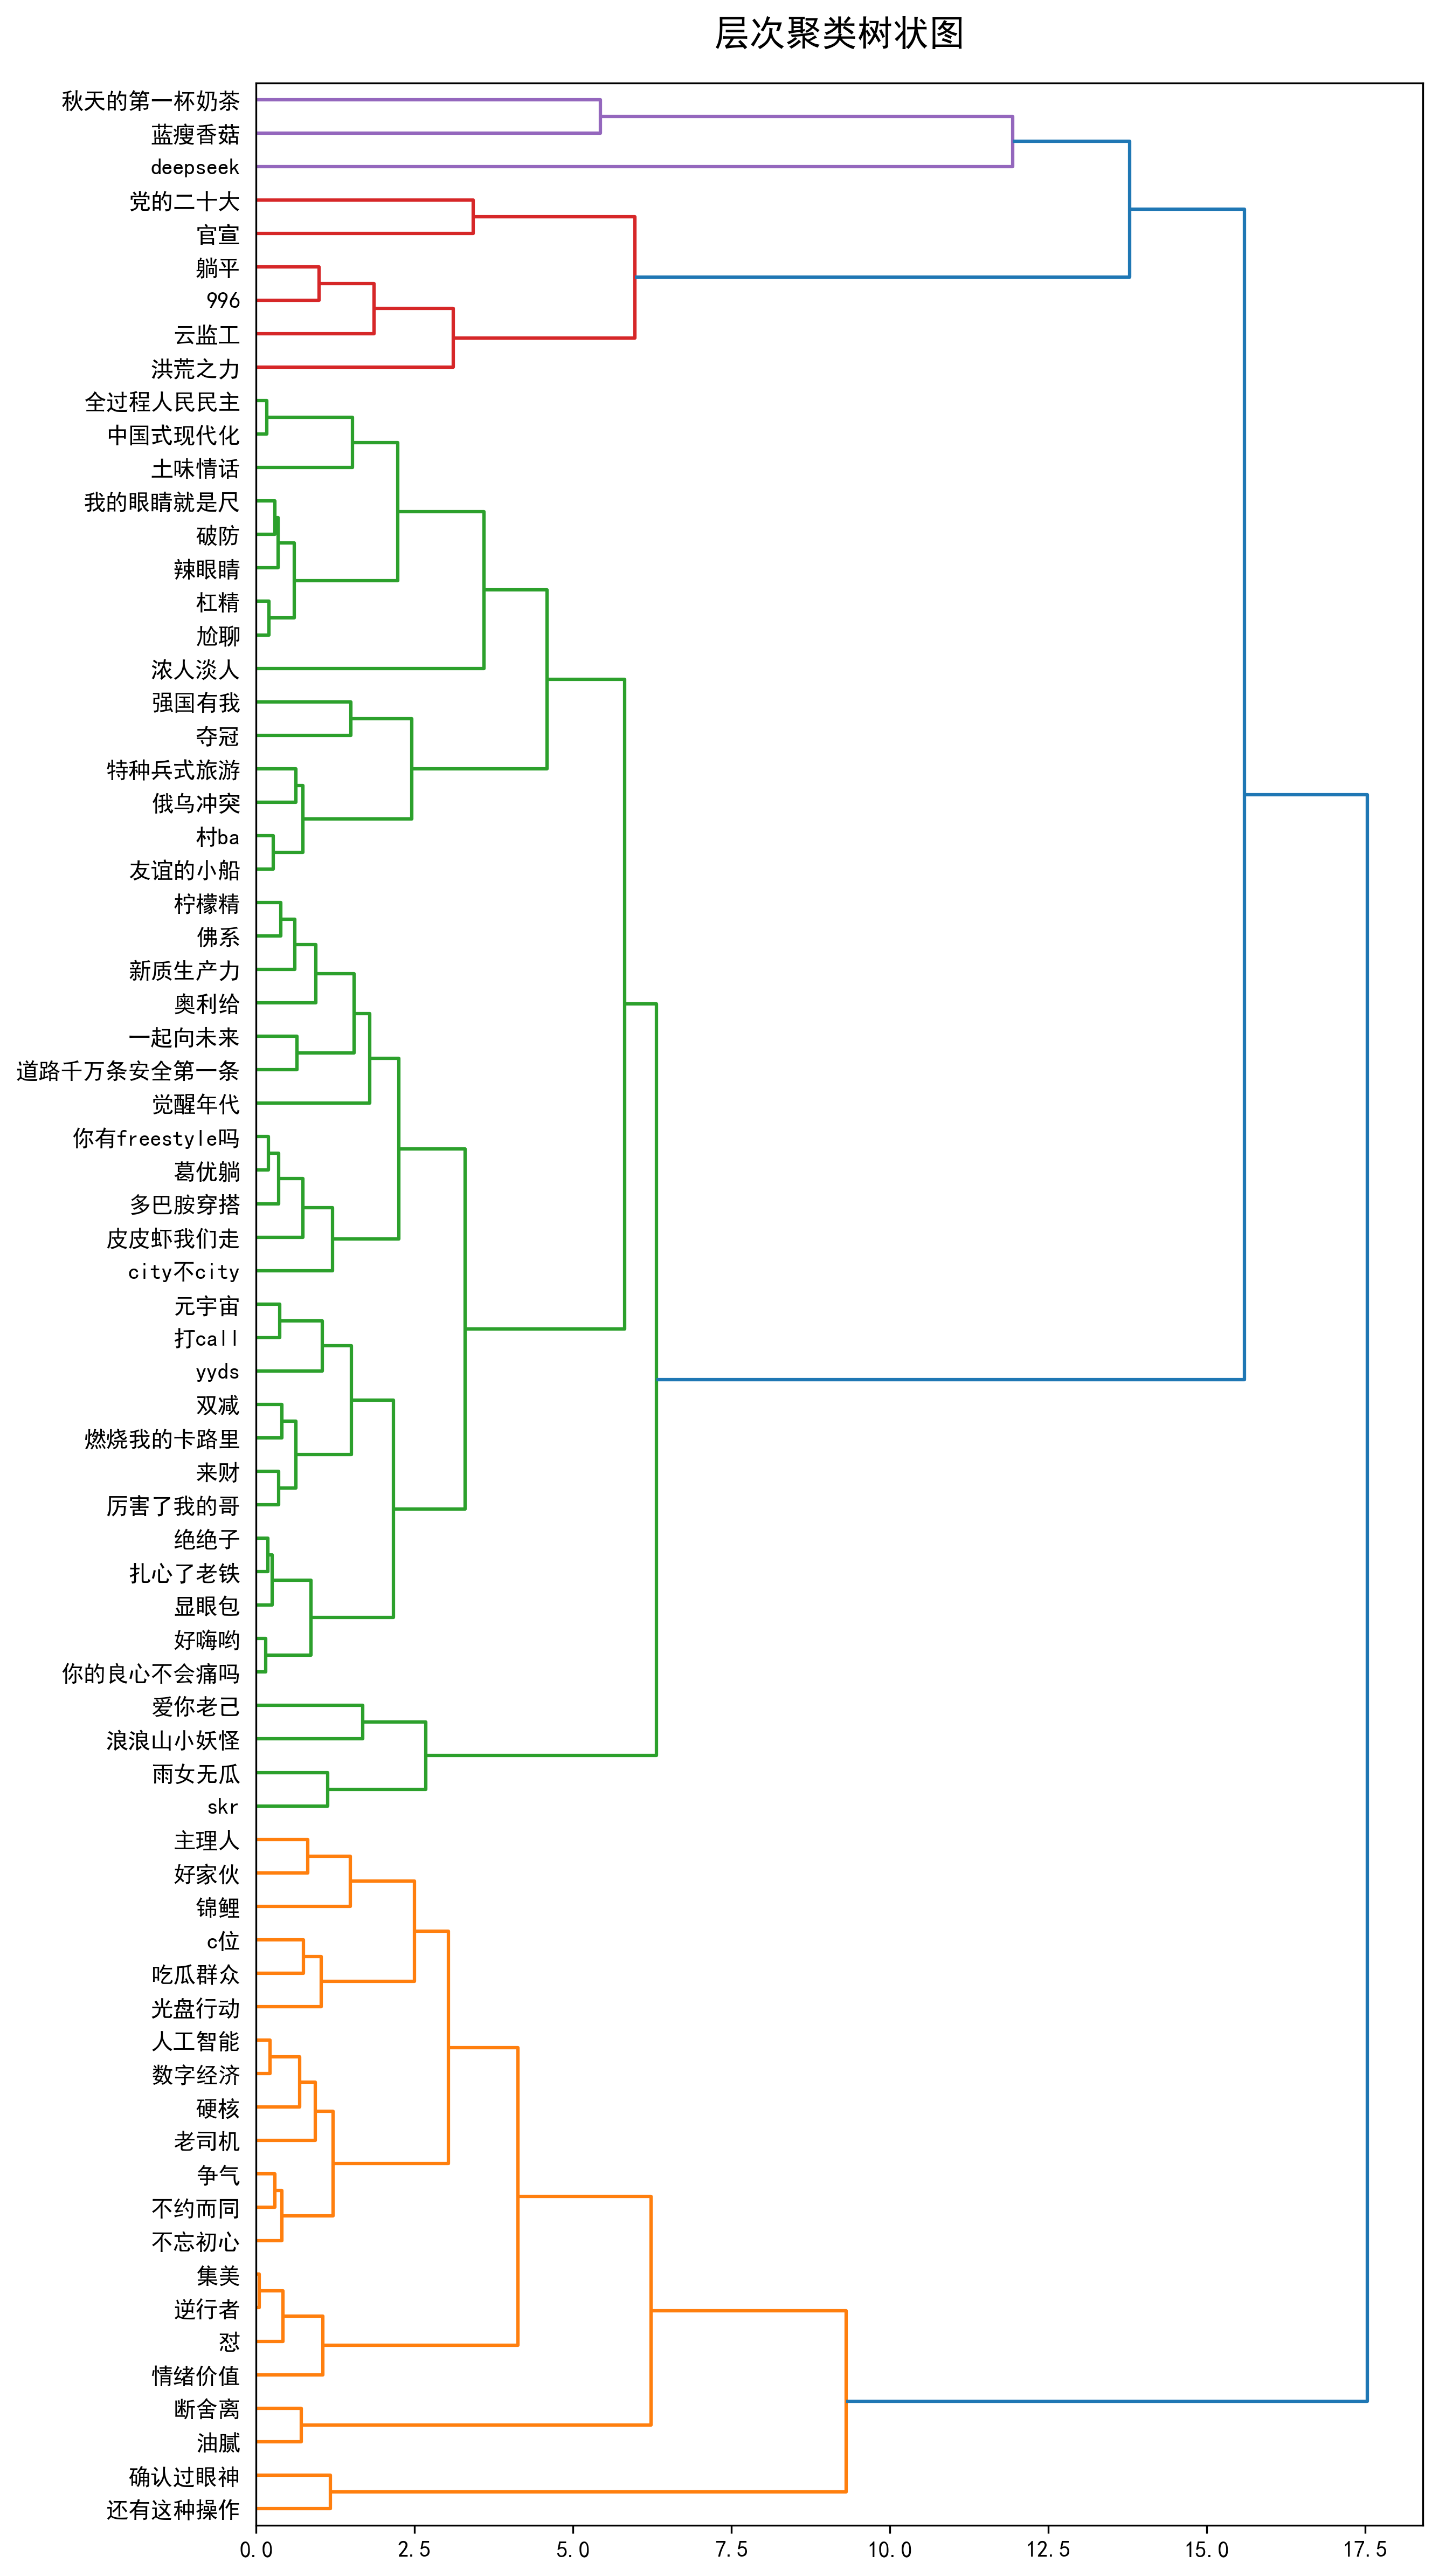

In [643]:
#此处简单进行层次聚类，信息参考另一位同学，此处只进行可视化调整
Z=linkage(df_feature_scaled[columns], method='ward')

#画布和分辨率设置
plt.figure(figsize=(9,16),dpi=300)

#进行旋转，竖着放置层次聚类图，并向右边聚
dendrogram(Z,labels=df_feature_scaled['keyword'].values,leaf_rotation=0,orientation='right')

#进行标题和标签的位置、大小设置
plt.title('层次聚类树状图',y=1.01,fontsize=16)
plt.tick_params(axis='y',labelsize=10)
plt.tight_layout()

# plt.savefig("层次聚类.png",dpi=300,bbox_inches='tight')
plt.show()

In [650]:

sse = []
for k in range(1,11):
    km = KMeans(n_clusters=k,random_state=42,n_init=20)
    km.fit(X_scaled)
    sse.append(km.inertia_)

best_k = 3
kmeans = KMeans(n_clusters=best_k,random_state=42,n_init=20)
data['kmeans_cluster'] = kmeans.fit_predict(X_scaled)+1

# PCA绘图
plt.figure(figsize=(10,7))
sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=data['kmeans_cluster'],
    palette='Set2',
    s=100
)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(df_feature_scaled[columns])


plt.title('K-Means聚类结果', fontsize=16)
plt.xlabel('主成分1', fontsize=12)
plt.ylabel('主成分2', fontsize=12)

# 原生手动标注，不加自动避让
for i, txt in enumerate(data['keyword']):
    # 文字向右上偏移，避免压在圆点上
    plt.text(X_pca[i,0]+0.06, X_pca[i,1]+0.06, txt, fontsize=9)

plt.legend(title='聚类类别')
plt.tight_layout()
# plt.savefig("Kmeans_PCA.png",dpi=300,bbox_inches='tight')
plt.show()

NameError: name 'X_pca' is not defined

<Figure size 1000x700 with 0 Axes>

## （二）描述统计部分可视化

### 1.整体热词数据描述统计
#### （1）归一化后的features值呈现

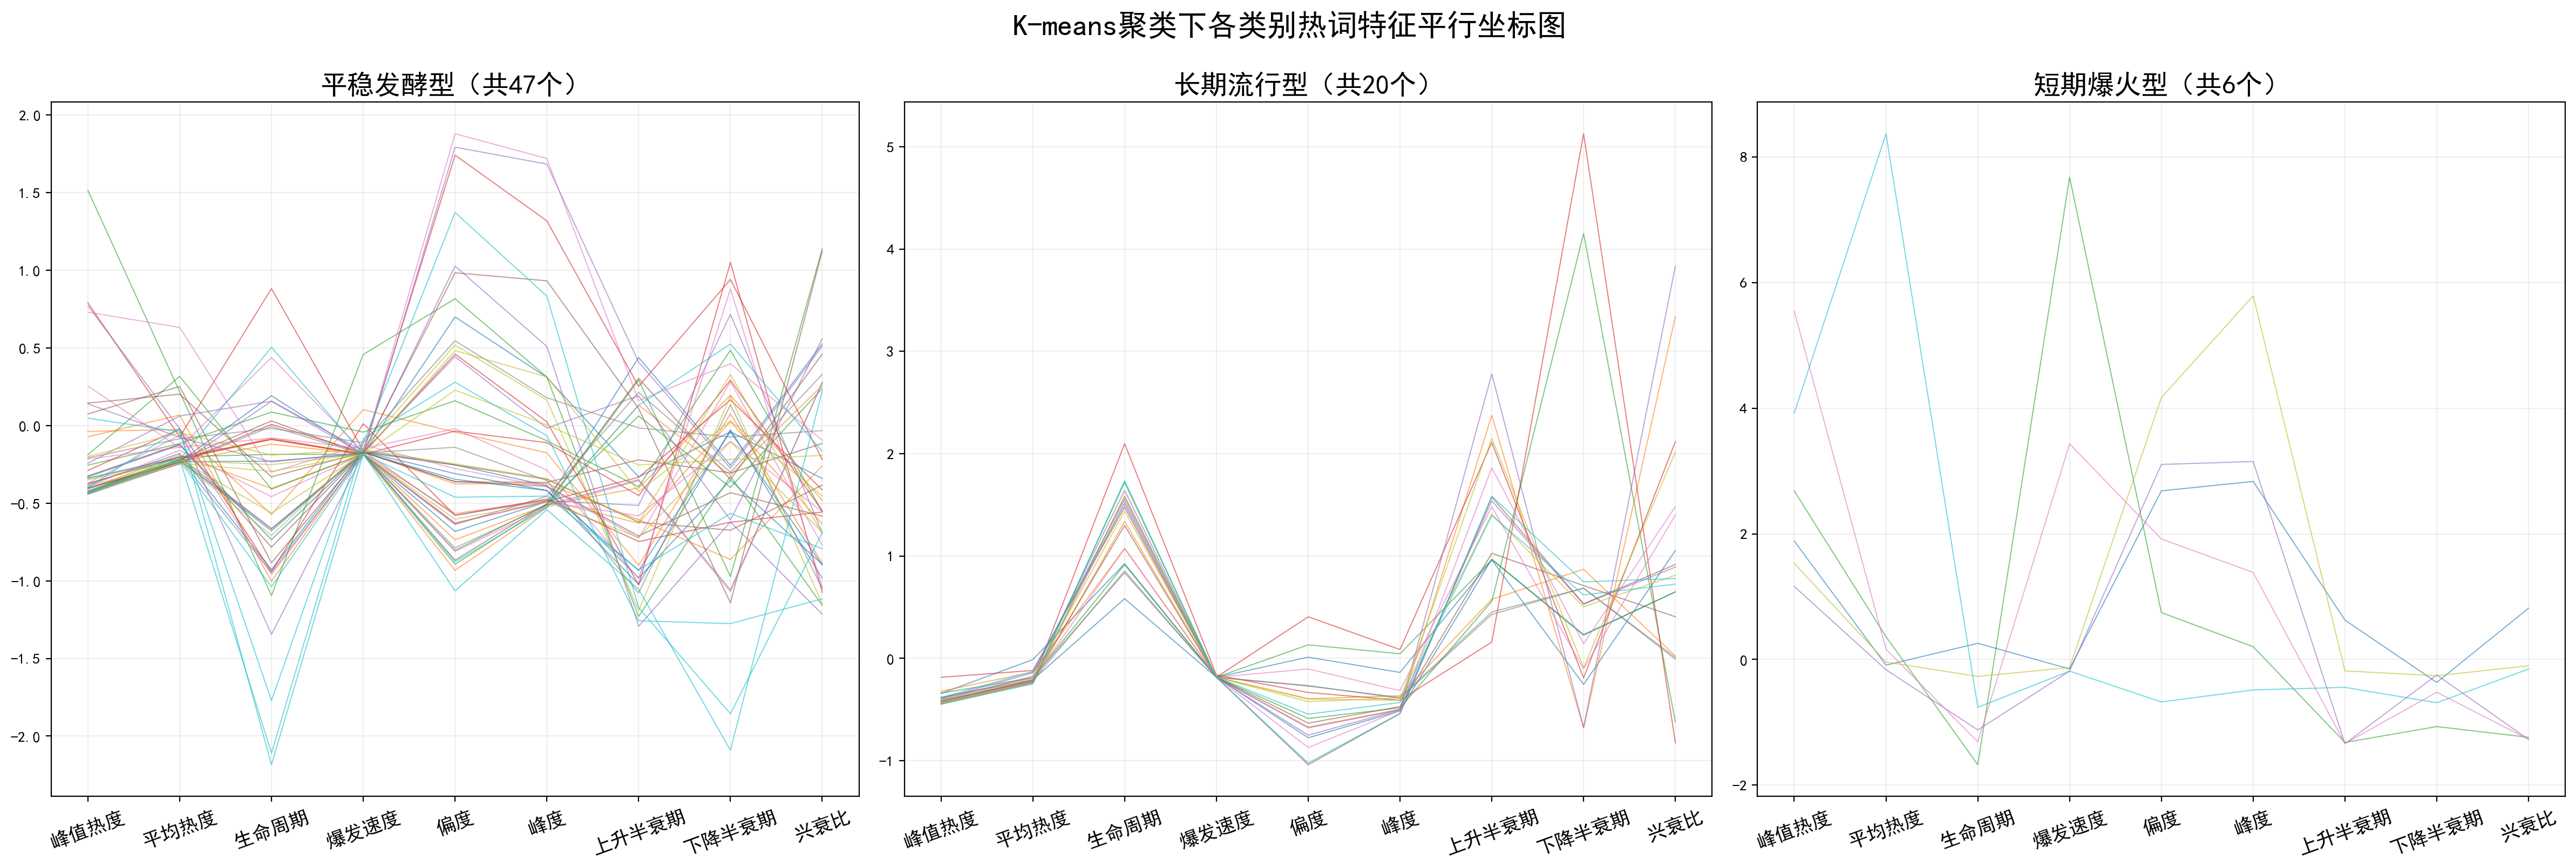

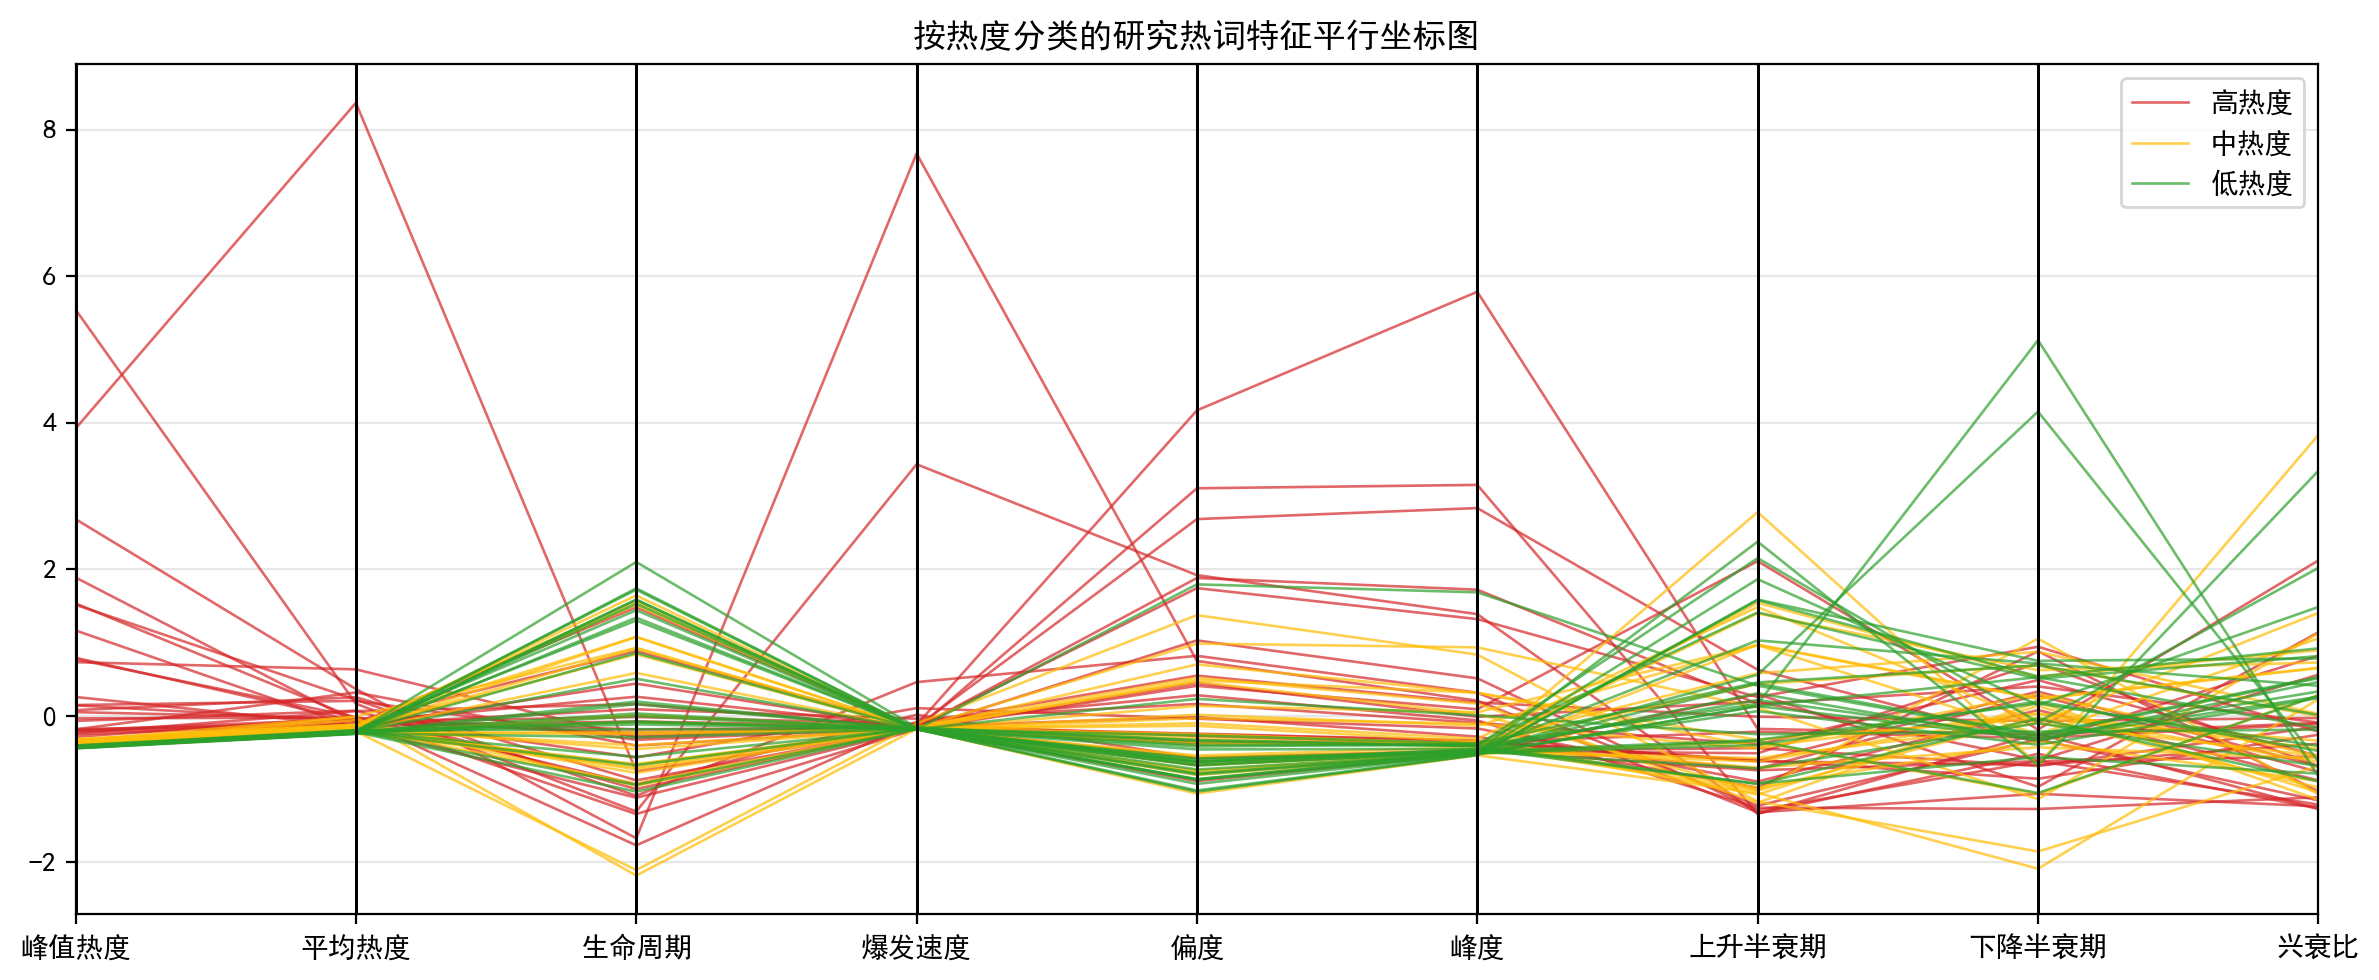

In [623]:
#（一）按K-means分类进行绘制
# 1.创建1行3列的图
# 注：该画法的画布分布与各画布设置方法向AI学来
fig,axes=plt.subplots(1,3,figsize=(24,8),dpi=200)
fig.suptitle('K-means聚类下各类别热词特征平行坐标图',fontsize=20,y=1)

# 2.通过for循环自动画出三个类别各自的、相关统计数据的平行坐标图
# 注：unique()函数由AI学习而来，可筛选不重复的值，就不用再单独构造列表
# 注：enumerate()用法由AI提供，可在获取数据同时获取序号用于分别画图
for i,cluster in enumerate(df_feature_scaled['cluster'].unique()):

    # 1）通过选择第i个子图,进行外层循环数据筛选
    select_ax=axes[i]
    df_loop1=df_feature_scaled[df_feature_scaled['cluster']==cluster]
    
    # 2）设置线条颜色
    # 注：该颜色设置方法询问AI得来
    line_colors=tab10(np.linspace(0,1,len(df_loop1)))
    
    # 3）设置x坐标，及坐标名
    x=list(range(len(columns)))
    xtick_label=['峰值热度','平均热度','生命周期','爆发速度','偏度','峰度','上升半衰期','下降半衰期','兴衰比']
    
    # 4）画平行坐标图，本可用parallel_coordinate直接进行绘制，但其只能通过class_column的输入控制颜色，所以放弃
    # 注：iterrows()由向AI学习而来，可遍历每行，返回该行所有数据的同时也返回行号
    n=len(df_feature_scaled[df_feature_scaled['cluster']==cluster])
    for j in range(n):
        #通过j取行再筛选列，确定y值
        y=df_loop1.iloc[j][columns].values
        
        #绘制第i个子图
        select_ax.plot(x,y,c=line_colors[j],alpha=0.6,linewidth=0.7)
    
        #设置图表的相应信息，包括标题、x轴的对应标签名等
        select_ax.set_title(f'{cluster}（共{n}个）',fontsize=18)
        select_ax.set_xticks(x)  
        select_ax.set_xticklabels(xtick_label,fontsize=13,rotation=20)
        select_ax.grid(alpha=0.2)

# 3.输出结果
plt.tight_layout()
plt.savefig(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\charts\K-means聚类下各类别热词特征平行坐标图.png",
            dpi=300,bbox_inches='tight',pad_inches=0.2)
plt.show()


#（二）按热度分类进行绘制
# 1.设置画布
plt.figure(figsize=(12,5),dpi=200)

# 将分类好的热度加入标准化的数据集中
df_feature_scaled['热度等级']=df_type['热度等级'].values

# 将类别与颜色通过元组配对，为后文设置不同类别的颜色做准备
index_and_color_list=[
    ("高热度", "#d62728"),("中热度","#ffbc05"),("低热度","#2ca02c")
]

# 2.利用for循环分别画出每个类别，最后统一输出在画布上
for index_type,color in index_and_color_list:
    df_loop=df_feature_scaled[df_feature_scaled['热度等级']==index_type]
    #利用parallel_coordinates画平行坐标图，输入相应参数
    # 注：该图的绘制方法parallel_coordinates的使用语法由AI学习而来
    parallel_coordinates(df_loop,class_column='热度等级',cols=columns,color=color,alpha=0.7,lw=0.95) 

# 3.设置该图其他相关信息
plt.title("按热度分类的研究热词特征平行坐标图")
plt.xticks(range(len(columns)),xtick_name)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\charts\按热度分类的研究热词特征平行坐标图.png",
            dpi=300,bbox_inches='tight',pad_inches=0.2)
plt.show()

#### （2）未归一化feature数据呈现

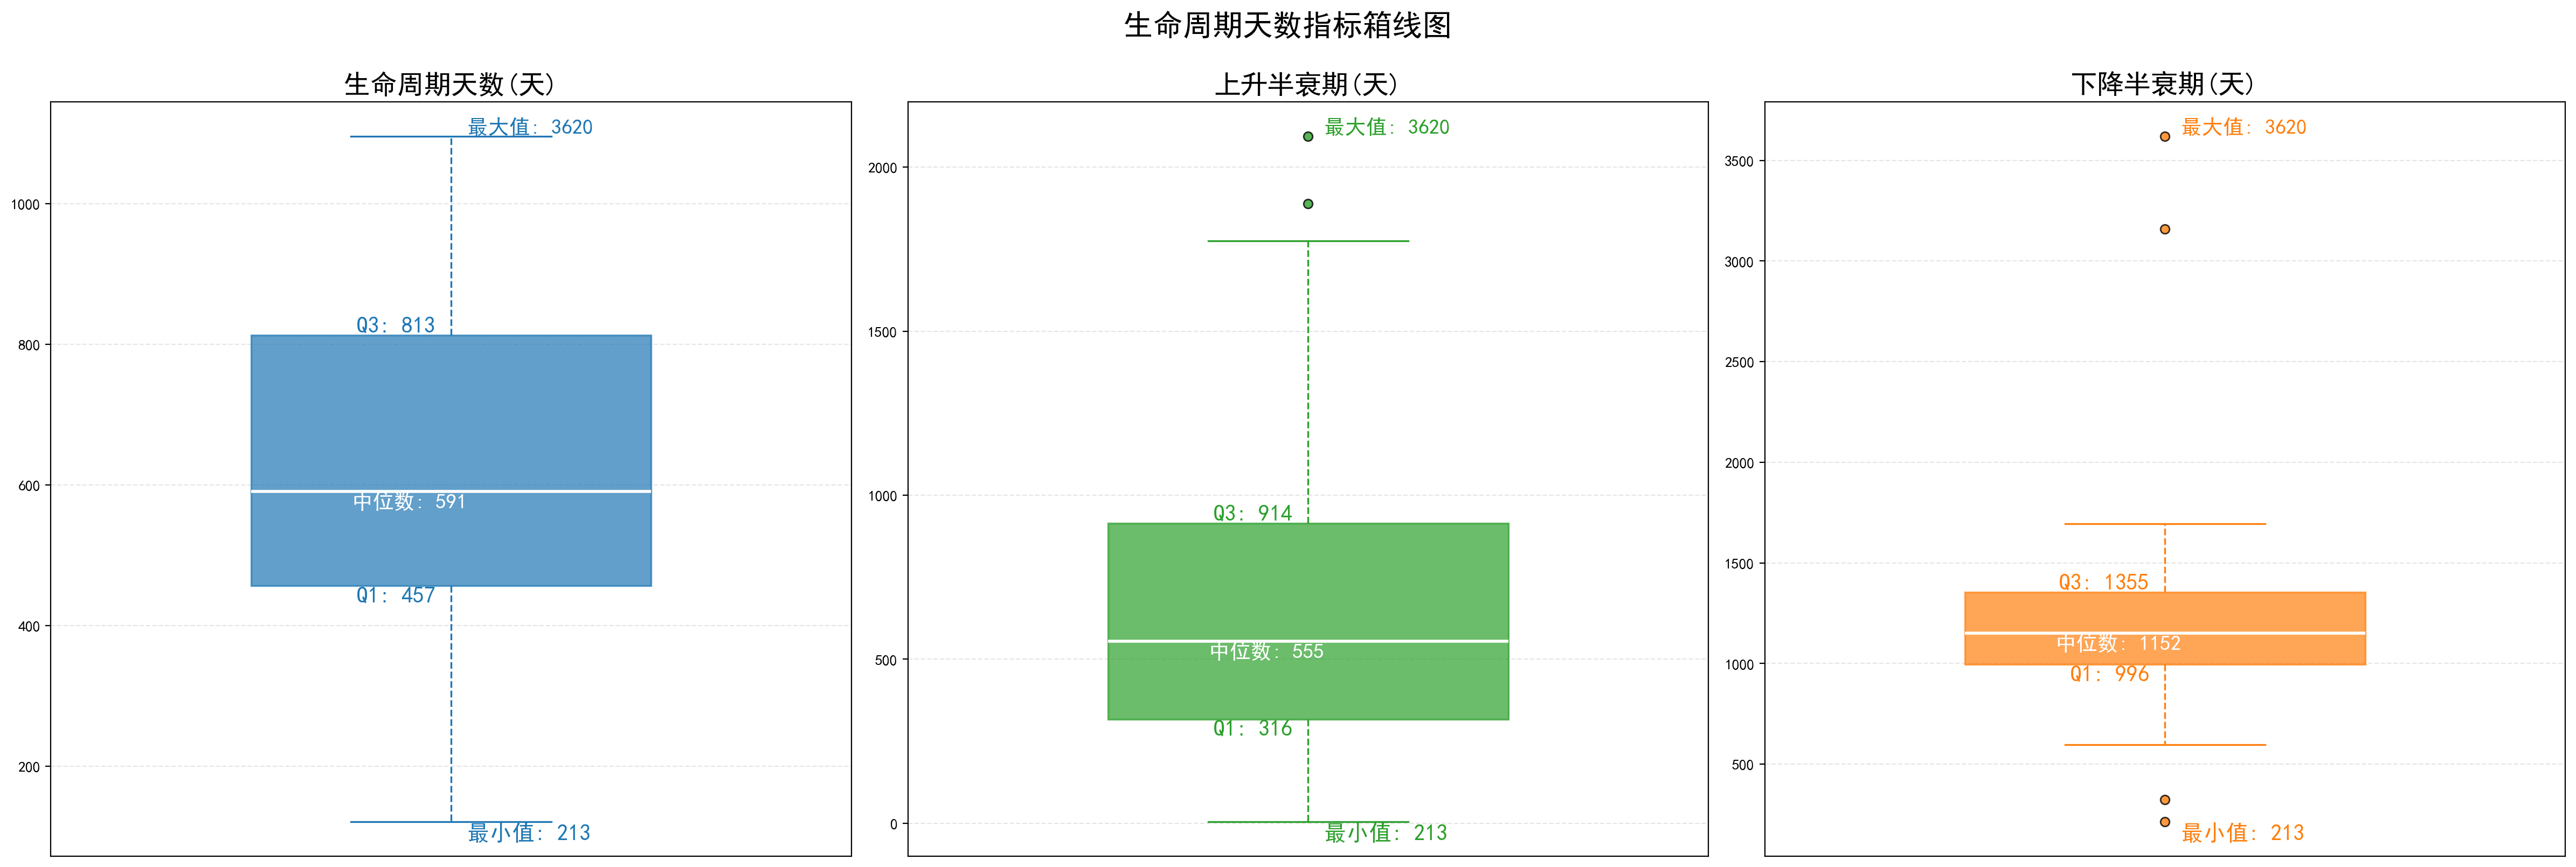

In [624]:
# 1.生命周期与半衰期天数箱线图
#设置画布，同上上图
fig,axes=plt.subplots(1,3,figsize=(24,8),dpi=200)
fig.suptitle('生命周期天数指标箱线图', fontsize=20, y=1)

#建立元组用于循环的对应
index_and_col_list=[
    (0,"lifecycle_days","生命周期天数","#1f77b4"),
    (1,"rise_half_life","上升半衰期","#2ca02c"),
    (2,"fall_half_life","下降半衰期","#ff7f0e")
]

#通过for循环画出生命周期天数的三个箱型图
for i,column,title,color in index_and_col_list:
    
    #选择子图
    select_ax=axes[i]
    
    #取列值，计算四分位及极值，为下面写值做准备
    # 注：四分位数计算的部分函数由AI提供
    data=df_feature[column]
    Q1=np.percentile(data,25)
    Q2=np.median(data)
    Q3=np.percentile(data, 75)
    min=np.min(data)
    max=np.max(data)
    
    #绘制箱线图并设置格式
    #注：以下设置箱型图的whiskerprop等语法求助AI展开设置，并自行进行调整
    select_ax.boxplot(
        #输入数据和基础的颜色允许、宽度设置
        data,patch_artist=True,widths=0.5,
        #设置箱子的格式
        boxprops=dict(facecolor=color,alpha=0.7,edgecolor=color,linewidth=1.2),
        #设置中位数的线
        medianprops=dict(color='white',linewidth=2,linestyle='-'),
        #设置线样式
        whiskerprops=dict(color=color,linewidth=1.2,linestyle='--'),
        #设置顶部与底部的线
        capprops=dict(color=color,linewidth=1.2),
        #设置异常值格式
        flierprops=dict(marker='o',markerfacecolor=color,markersize=6,alpha=0.8)
    )
    
    #设置网格
    select_ax.grid(axis='y',alpha=0.2,linestyle='--',color='grey')
    #因为不设置该项子图下会默认出现-1-故求助AI删除
    select_ax.set_xticks([])
    #设置子图标题和单位
    select_ax.set_title(f'{title}(天)',fontsize=18)
  
    #设置四分位数及最值的格式
    # 注：格式设置参考AI并自行做出一些调整
    select_ax.text(1.02, Q2, f'中位数: {Q2:.0f}',va='top',ha='right',color='white',fontsize=14)
    select_ax.text(0.98, Q1, f'Q1: {Q1:.0f}',va='top',ha='right',fontsize=15,color=color)
    select_ax.text(0.98, Q3, f'Q3: {Q3:.0f}',va='bottom',ha='right',fontsize=15,color=color)
    select_ax.text(1.02, min, f'最小值: {min_val:.0f}',va='top',fontsize=15,color=color)
    select_ax.text(1.02, max, f'最大值: {max_val:.0f}',va='bottom',fontsize=14,color=color)

#调整输出
plt.tight_layout()
plt.savefig(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\charts\生命周期天数指标箱线图.png",
            dpi=300,bbox_inches='tight',pad_inches=0.2)
plt.show()

### 2.典型热词生命周期变化呈现

#### ——根据聚类中心距离最小取不同类型典型热词，绘制生命周期变化曲线

各聚类最典型的3个关键词：
平稳发酵型: 特种兵式旅游, 双减, 柠檬精
长期流行型: 数字经济, 人工智能, 不忘初心
短期爆火型: 官宣, 洪荒之力, 秋天的第一杯奶茶


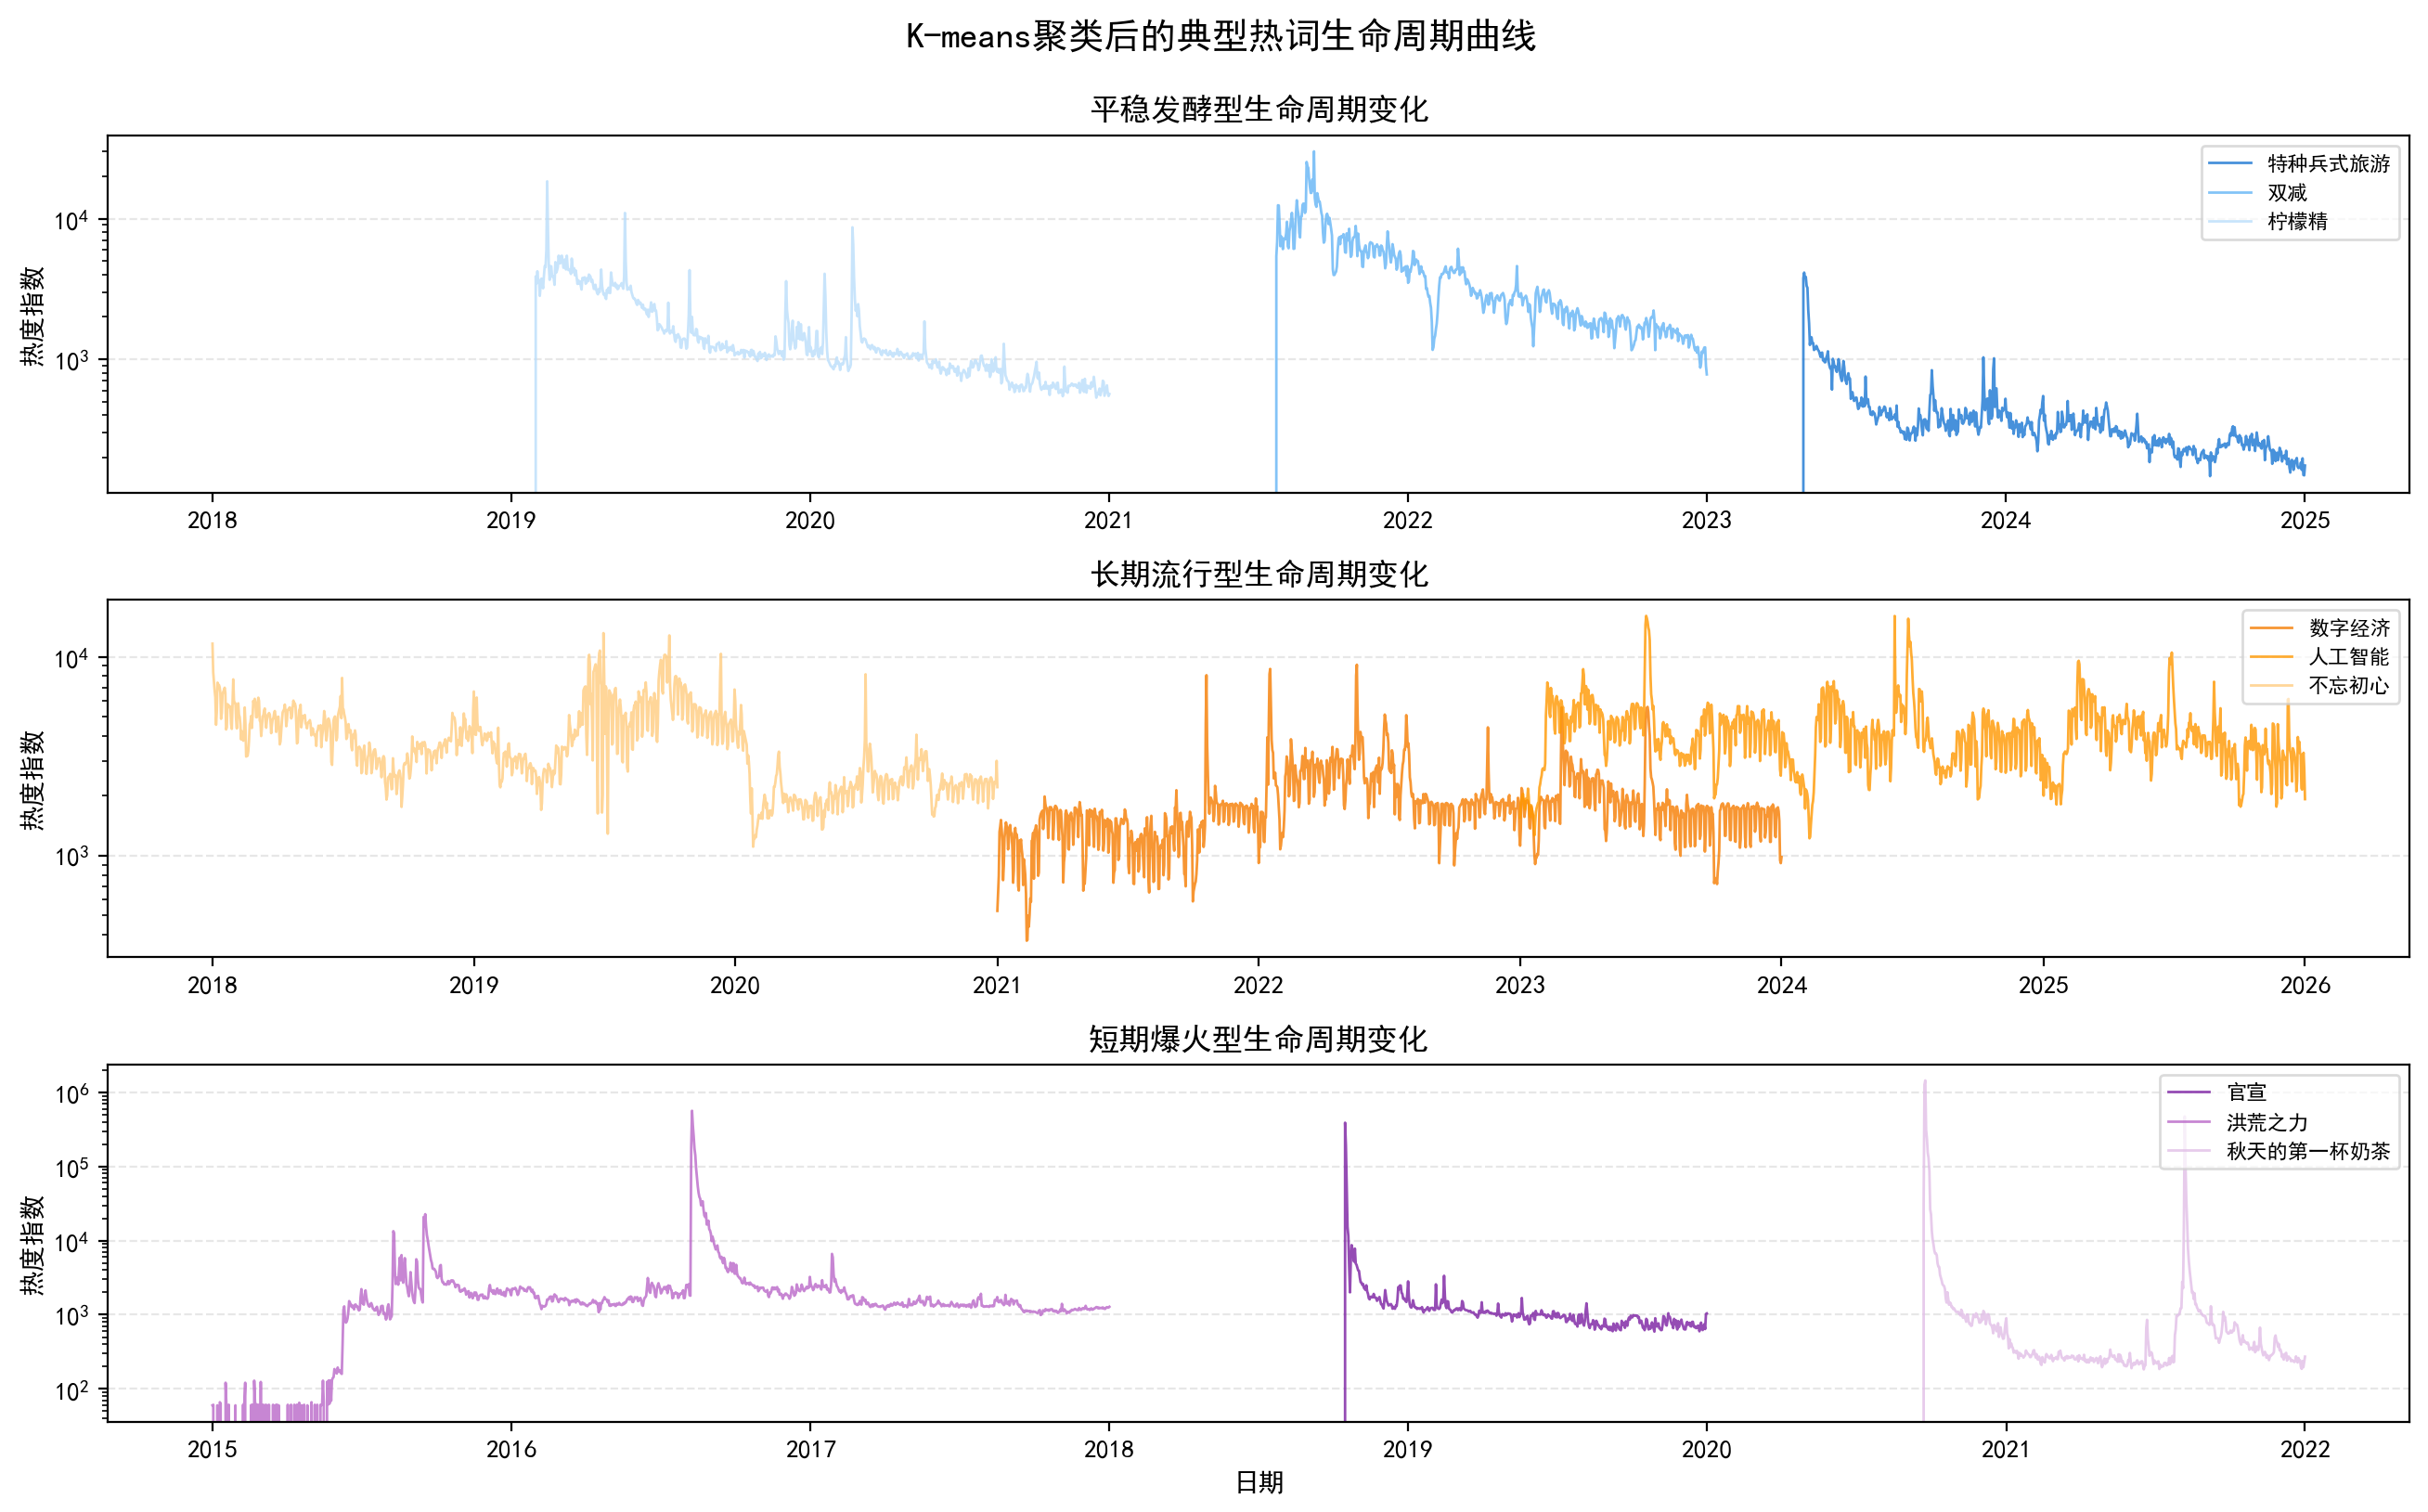

In [625]:
# 1.注：通过计算中心距离，取最小值画典型热词的办法由AI提供思路和完成距离计算部分代码的撰写
# 1）计算每个聚类的中心
centers = {}
for cluster_name in df_feature_scaled['cluster'].unique():
    cluster_data = df_feature_scaled[df_feature_scaled['cluster'] == cluster_name]
    centers[cluster_name] = cluster_data[columns].mean().values
    
# 2）计算每个样本到其所属聚类中心的欧氏距离
distances = []
for idx, row in df_feature_scaled.iterrows():
    cluster = row['cluster']
    center = centers[cluster]
    point = row[columns].values
    dist = np.linalg.norm(point - center)
    distances.append(dist)
df_feature_scaled['dist_to_center'] = distances

# 3）每个聚类按距离排序，选取前3个最小距离的关键词（最典型）
typical_keywords = {}
for cluster_name in df_feature_scaled['cluster'].unique():
    sub = df_feature_scaled[df_feature_scaled['cluster'] == cluster_name]
    sub_sorted = sub.sort_values('dist_to_center')
    # 取前3个关键词，如果不足3个则取全部
    top3 = sub_sorted['keyword'].head(3).tolist()
    typical_keywords[cluster_name] = top3

# 4）输出结果
print("各聚类最典型的3个关键词：")
for cluster, words in typical_keywords.items():
    print(f"{cluster}: {', '.join(words)}")


# 2.注：根据AI code的距离计算得到典型热词，然后本人再进行绘制
#开始画图
# 1）准备工作
#设置颜色、关键词字典和子图绘图顺序相关准备工作
#注：具体的颜色设置由AI提供
keywords={
    "平稳发酵型":["特种兵式旅游","双减","柠檬精"],
    "长期流行型":["数字经济","人工智能","不忘初心"],
    "短期爆火型":["官宣","洪荒之力","秋天的第一杯奶茶"]
}
colors={
    "长期流行型": ["#F57C00", "#FF9800", "#FFCC80"],
    "短期爆火型": ["#7B1FA2", "#BA68C8", "#E1BEE7"],
    "平稳发酵型": ["#1976D2", "#64B5F6", "#BBDEFB"]
}
order=[(0,"平稳发酵型"),(1,"长期流行型"),(2,"短期爆火型")]

# 2）画图
#创建3行1列的子图
fig,axes=plt.subplots(3,1,figsize=(16,9),dpi=200)

#通过for循环依此画图
for i,t in order:
    #外层循环：根据类型确认子图，及相对应的关键词和颜色列表
    this_ax=axes[i]
    this_keyword=keywords[t]
    this_color=colors[t]

    #内循环，进一步进行关键词和颜色一一对应并循环绘制
    for j,k in enumerate(this_keyword):
        df_this_turn=df_index[df_index["关键词"]==k]
        this_ax.plot(df_this_turn["日期"],df_this_turn["全部"],c=this_color[j],label=k,lw=1,alpha=0.8)
    
    #内循环完成，即一个子图完成，进行子图相关信息设置
    # 注：部分设置由询问AI得来
    this_ax.set_title(f"{t}生命周期变化",fontsize=12)
    this_ax.set_ylabel("热度指数")
    this_ax.set_yscale("log")
    this_ax.legend(loc="upper right",fontsize=8,framealpha=0.7)
    this_ax.grid(axis="y",alpha=0.3,ls="--")
    this_ax.xaxis.set_major_locator(mdates.YearLocator(1))
    this_ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

#循环完成，设置不需要循环的相关信息
fig.subplots_adjust(hspace=0.3)
axes[-1].set_xlabel("日期")
fig.suptitle("K-means聚类后的典型热词生命周期曲线",fontsize=14,y=0.95)

# 3）输出
plt.savefig(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\charts\K-means聚类后的典型热词生命周期曲线.png",
            dpi=300,bbox_inches='tight',pad_inches=0.2)
plt.show()

### 3.不同指标的相关性分析

#### （1）散点矩阵图

<Figure size 9600x8800 with 0 Axes>

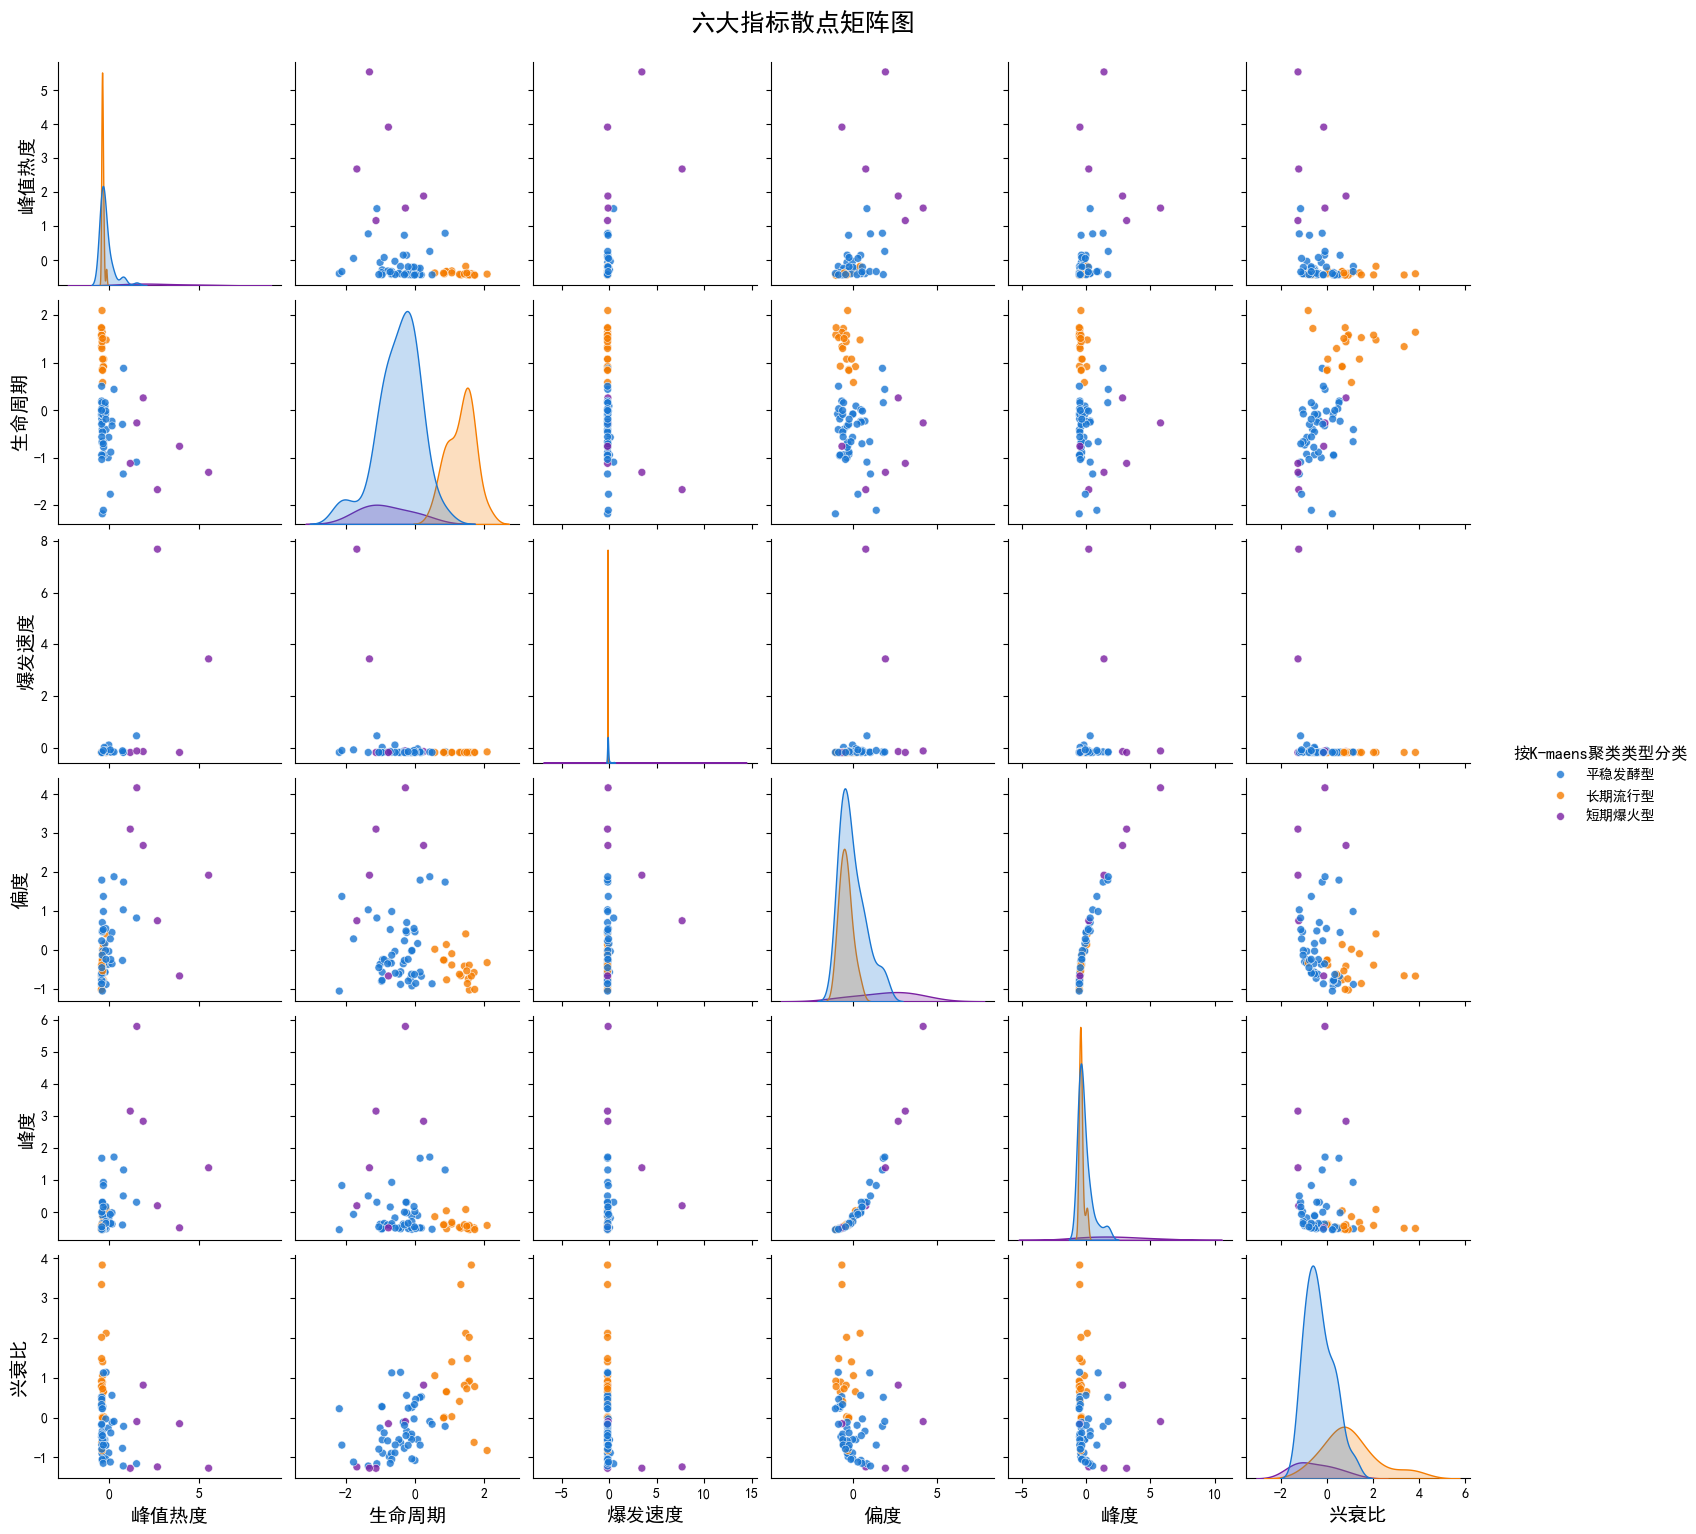

<Figure size 9600x8800 with 0 Axes>

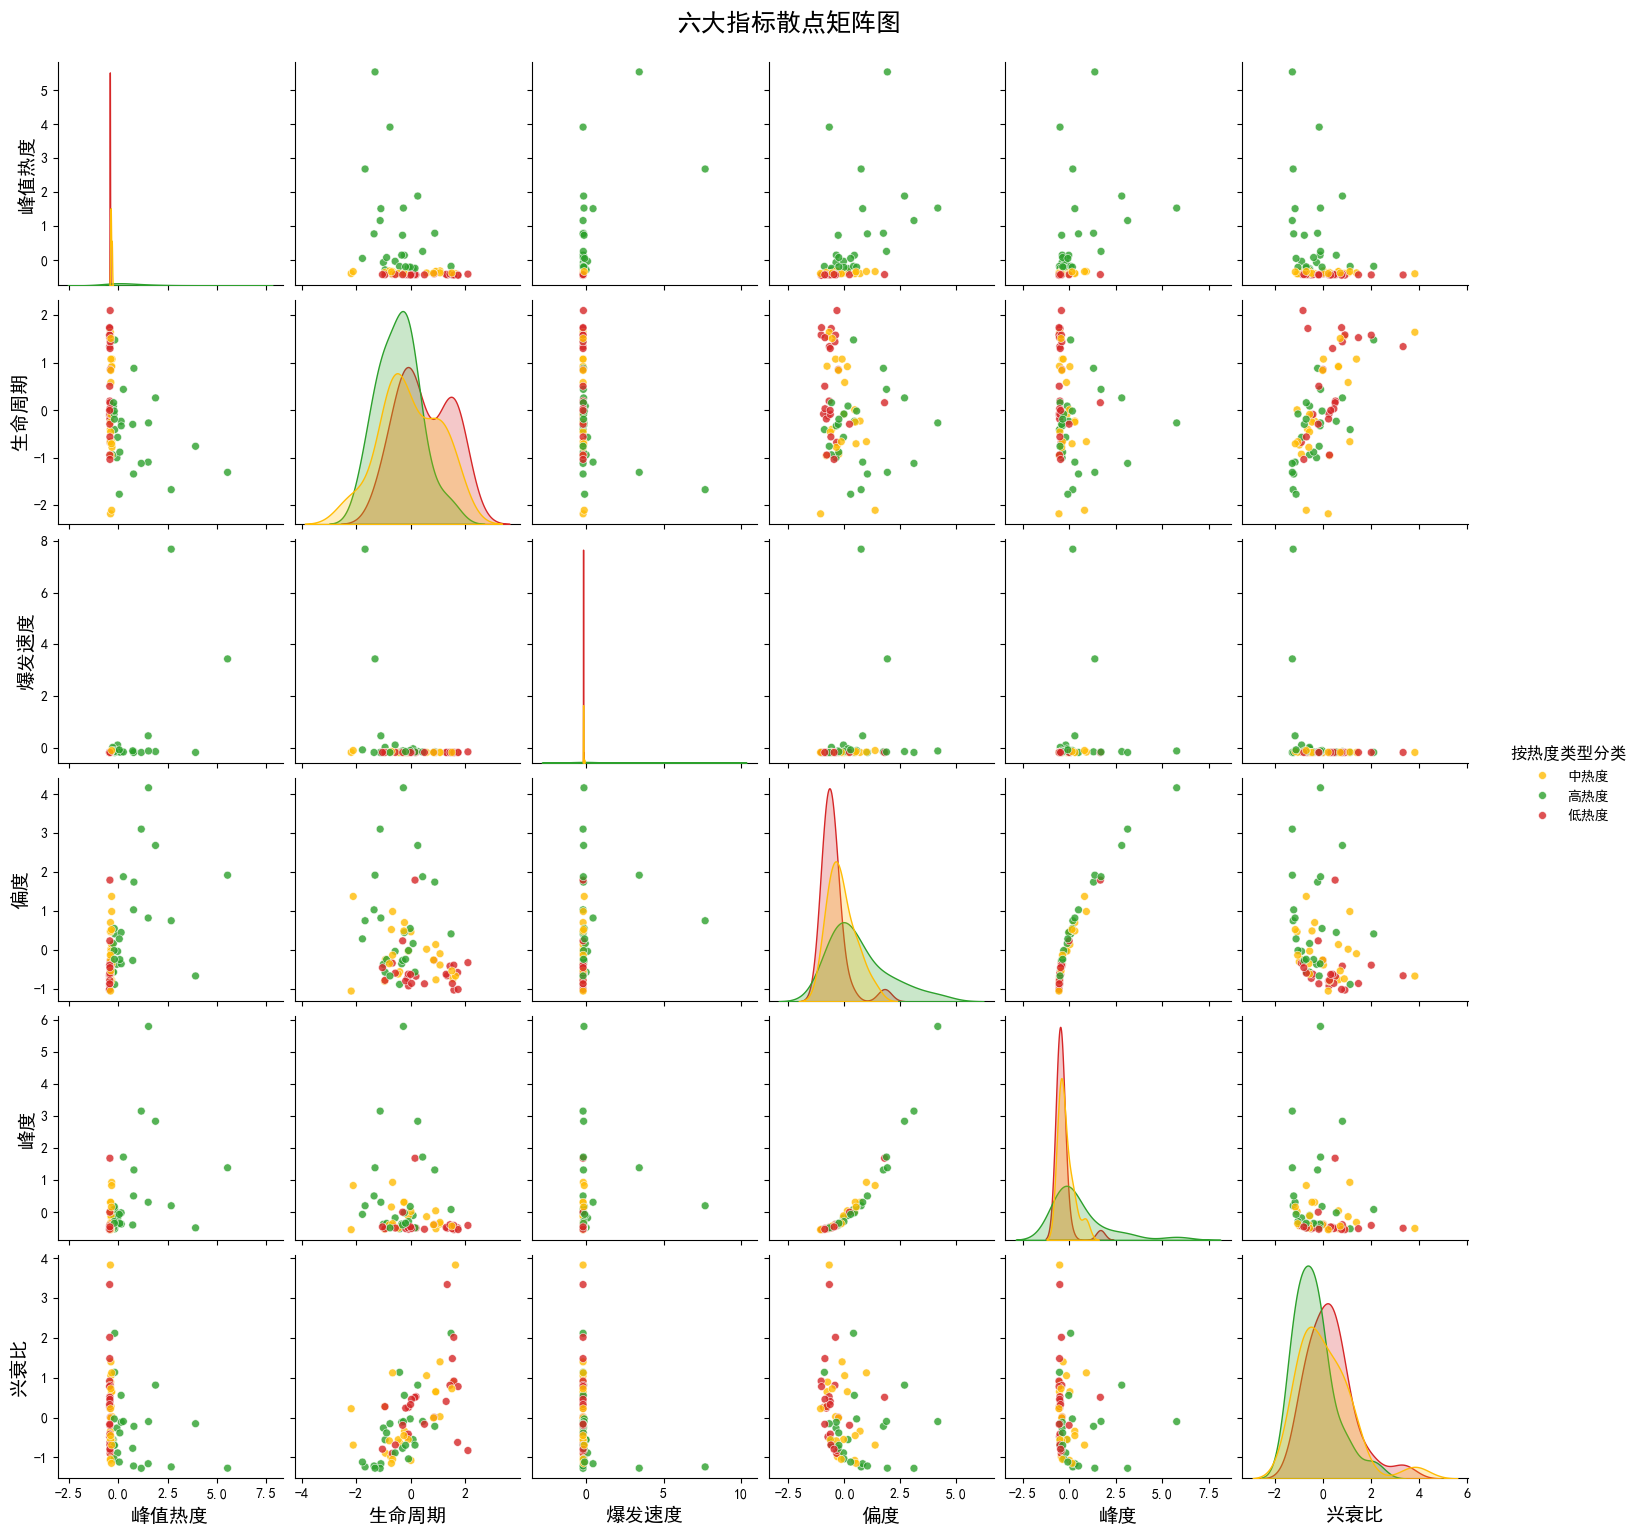

In [626]:
#准备工作，将要用到的列名和坐标轴的标签名列出
this_turn_columns=['peak','lifecycle_days','rise_speed','skewness','kurtosis','trend_ratio']
xticklabel=['峰值热度','生命周期','爆发速度','偏度','峰度','兴衰比']

# 1.按K-means聚类分
# 1）用字典设置配色
#  注：AI解释相关报错：palette无法识别像前面一样的元组写法，故此使用字典
pal_k={
    "长期流行型":"#F57C00","短期爆火型":"#7B1FA2","平稳发酵型":"#1976D2"
}

# 2）开始画图
# 注：该图的绘制sns.pairplot使用方法由AI提供
plt.figure(figsize=(24,22),dpi=400)
k_plot=sns.pairplot(df_feature_scaled[this_2_turn_columns+["cluster"]],
                    hue="cluster",palette=pal_k,diag_kind="kde",
                    plot_kws={"alpha":0.8,"s":32,"edgecolor":'white'})

# 3）设置图表相关信息，包括坐标轴的标签、标题、图例标题
# 注：k_plot.axes[-1,:]用于修改最底部一整行所有子图的X轴标签，由AI提供子图最底部一整行的表示方法，-1表示最后

# 设置坐标轴信息
for i,ax in enumerate(k_plot.axes[-1,:]):
    ax.set_xlabel(xticklabel[i],fontsize=14)
for i,ax in enumerate(k_plot.axes[:,0]):
    ax.set_ylabel(xticklabel[i],fontsize=14)

# 设置图例及标题信息
k_plot.legend.set_title("按K-maens聚类类型分类",prop={'size':12})
k_plot.legend.set_bbox_to_anchor((1.05, 0.5)) 
k_plot.fig.suptitle("六大指标散点矩阵图",y=1.02,fontsize=18)

# 4）输出结果
plt.savefig(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\charts\六大指标散点矩阵图(K-means).png",
            dpi=300,bbox_inches='tight',pad_inches=0.2)
plt.show()


# 2.按热度分类（流程与上图几乎完全一样，只需改变颜色与分类，将k改为index<即热度指标>）
# 1）设置配色
index_pal={
    "低热度":"#d62728","中热度":"#ffbc05","高热度":"#2ca02c"
}

# 2）开始画图
plt.figure(figsize=(24,22),dpi=400)
index_plot=sns.pairplot(df_feature_scaled[this_2_turn_columns+["热度等级"]],
                    hue="热度等级",palette=pal,diag_kind="kde",
                    plot_kws={"alpha":0.8,"s":32,"edgecolor":'white'})

# 3）设置图表相关信息，包括坐标轴的标签、标题、图例标题
# 设置坐标轴信息
for i,ax in enumerate(index_plot.axes[-1,:]):
    ax.set_xlabel(xticklabel[i],fontsize=14)
for i,ax in enumerate(index_plot.axes[:,0]):
    ax.set_ylabel(xticklabel[i],fontsize=14)

# 设置图例及标题信息
index_plot.legend.set_title("按热度类型分类",prop={'size':12})
index_plot.legend.set_bbox_to_anchor((1.03, 0.5)) 
index_plot.fig.suptitle("六大指标散点矩阵图",y=1.02,fontsize=18)

# 4）输出结果
plt.savefig(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\charts\六大指标散点矩阵图(热度).png",
            dpi=300,bbox_inches='tight',pad_inches=0.2)
plt.show()

#### （2）相关性热力图

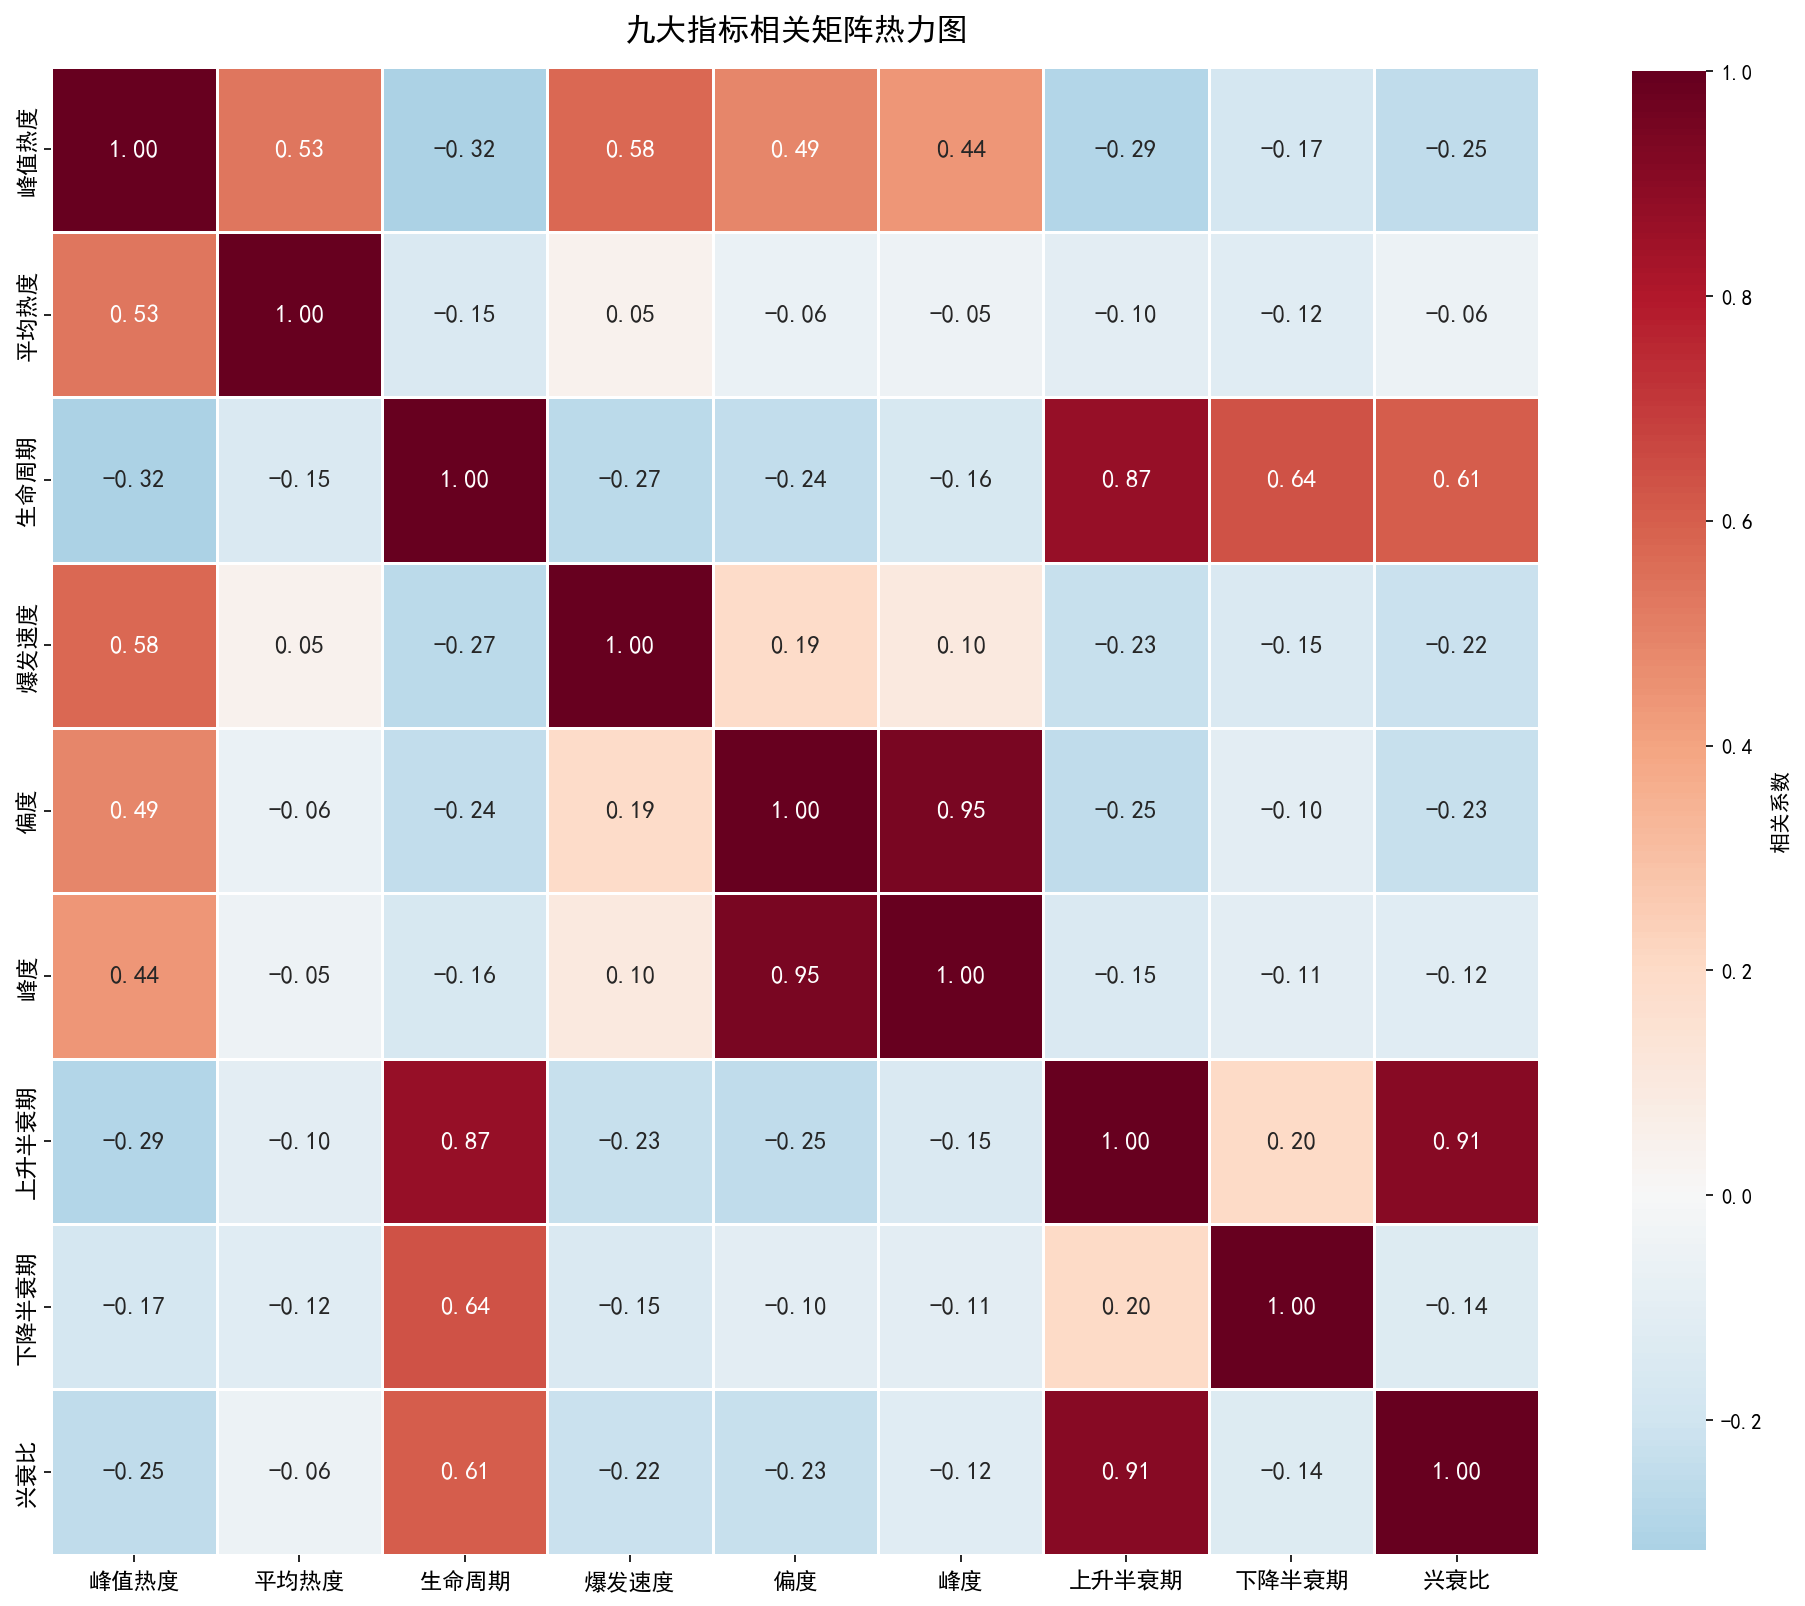

In [627]:
# 1）准备数据：利用原始数据，用皮尔逊相关系数，计算相关系数矩阵
# 注：计算函数corr()由AI提供
corr_matrix=df_feature[columns].corr()

# 2）开始画图
# 注：该图的绘制语法使用由AI提供，部分设置也由AI提供
plt.figure(figsize=(16,16),dpi=150) 
ax = sns.heatmap(
    corr_matrix,annot=True,fmt='.2f',
    #AI提供发散色建议
    cmap='RdBu_r',
    center=0,square=True,linewidths=0.5,
    cbar_kws={'shrink':0.8,'label': '相关系数'},annot_kws={'size':12} 
)

#设置相关坐标、标题等信息
ax.set_xticklabels(xtick_label,fontsize=11)
ax.set_yticklabels(xtick_label,fontsize=11)
plt.title('九大指标相关矩阵热力图',y=1.01,fontsize=15)
plt.savefig(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\charts\九大指标相关矩阵热力图.png",
            dpi=300,bbox_inches='tight',pad_inches=0.2)
plt.show()

### 3.聚类后的类别特征分析

#### ——聚类雷达图

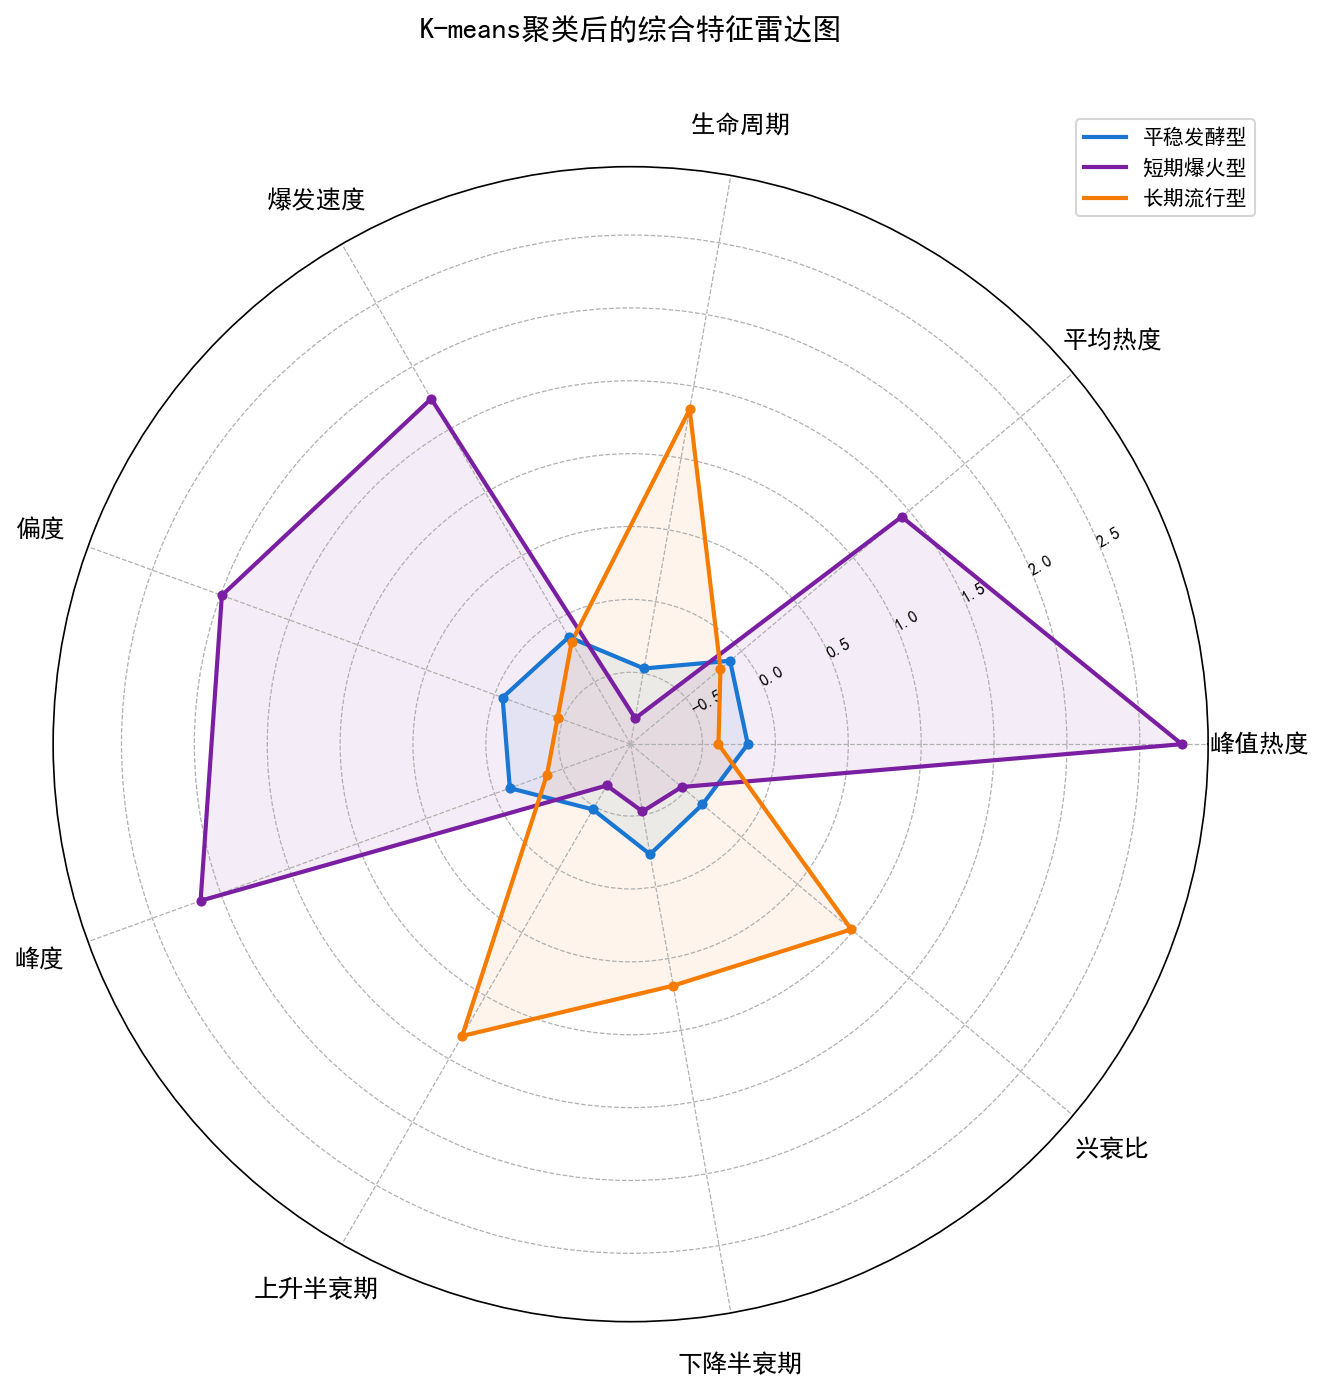

In [628]:
#注：此图代码主要由AI生成，本人根据自己需求只做了一定调整和不同AI生成代码的拼接
#按聚类求各指标平均值
radar_df=df_feature_scaled.groupby("cluster")[columns].mean().reset_index()

#计算每个指标对应的角度并合并
angles=np.linspace(0,2*np.pi,len(xtick_label),endpoint=False).tolist()
angles+=angles[:1]

#设置颜色
cluster_colors = {
    "长期流行型": "#F57C00",
    "短期爆火型": "#7B1FA2",
    "平稳发酵型": "#1976D2"
}

#设置画布
fig, ax = plt.subplots(figsize=(10,10),dpi=150,subplot_kw=dict(polar=True))

#绘图
for _, row in cluster_means.iterrows():
    cluster = row['cluster']
    color = cluster_colors[cluster]
    # 提取该聚类在各指标上的均值，并闭合
    values = row[feature_cols].values.flatten().tolist()
    values += values[:1]
    # 绘制折线
    ax.plot(angles, values, color=color, linewidth=2, label=cluster)
    # 填充半透明色
    ax.fill(angles, values, color=color, alpha=0.08)
    ax.scatter(angles[:-1], values[:-1], s=15, color=color,zorder=3)

#设置标签信息
ax.set_xticks(angles[:-1])
lab_list = ax.set_xticklabels(xtick_label, fontsize=12)
ax.tick_params(axis='x', pad=14)
ax.set_title("K-means聚类后的综合特征雷达图",y=1.1,fontsize=14)
ax.legend(loc='upper right', bbox_to_anchor=(1.05, 1.05))
ax.tick_params(axis='y',labelrotation=40,labelsize=9)
ax.grid(linewidth=0.6,linestyle='--')
ax.tick_params(axis='y', pad=9, labelrotation=30,labelsize=8)
plt.savefig(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\charts\K-means聚类后的综合特征雷达图.png",
            dpi=300,bbox_inches='tight',pad_inches=0.2)
plt.show()

### 4.整体传播形态分析图

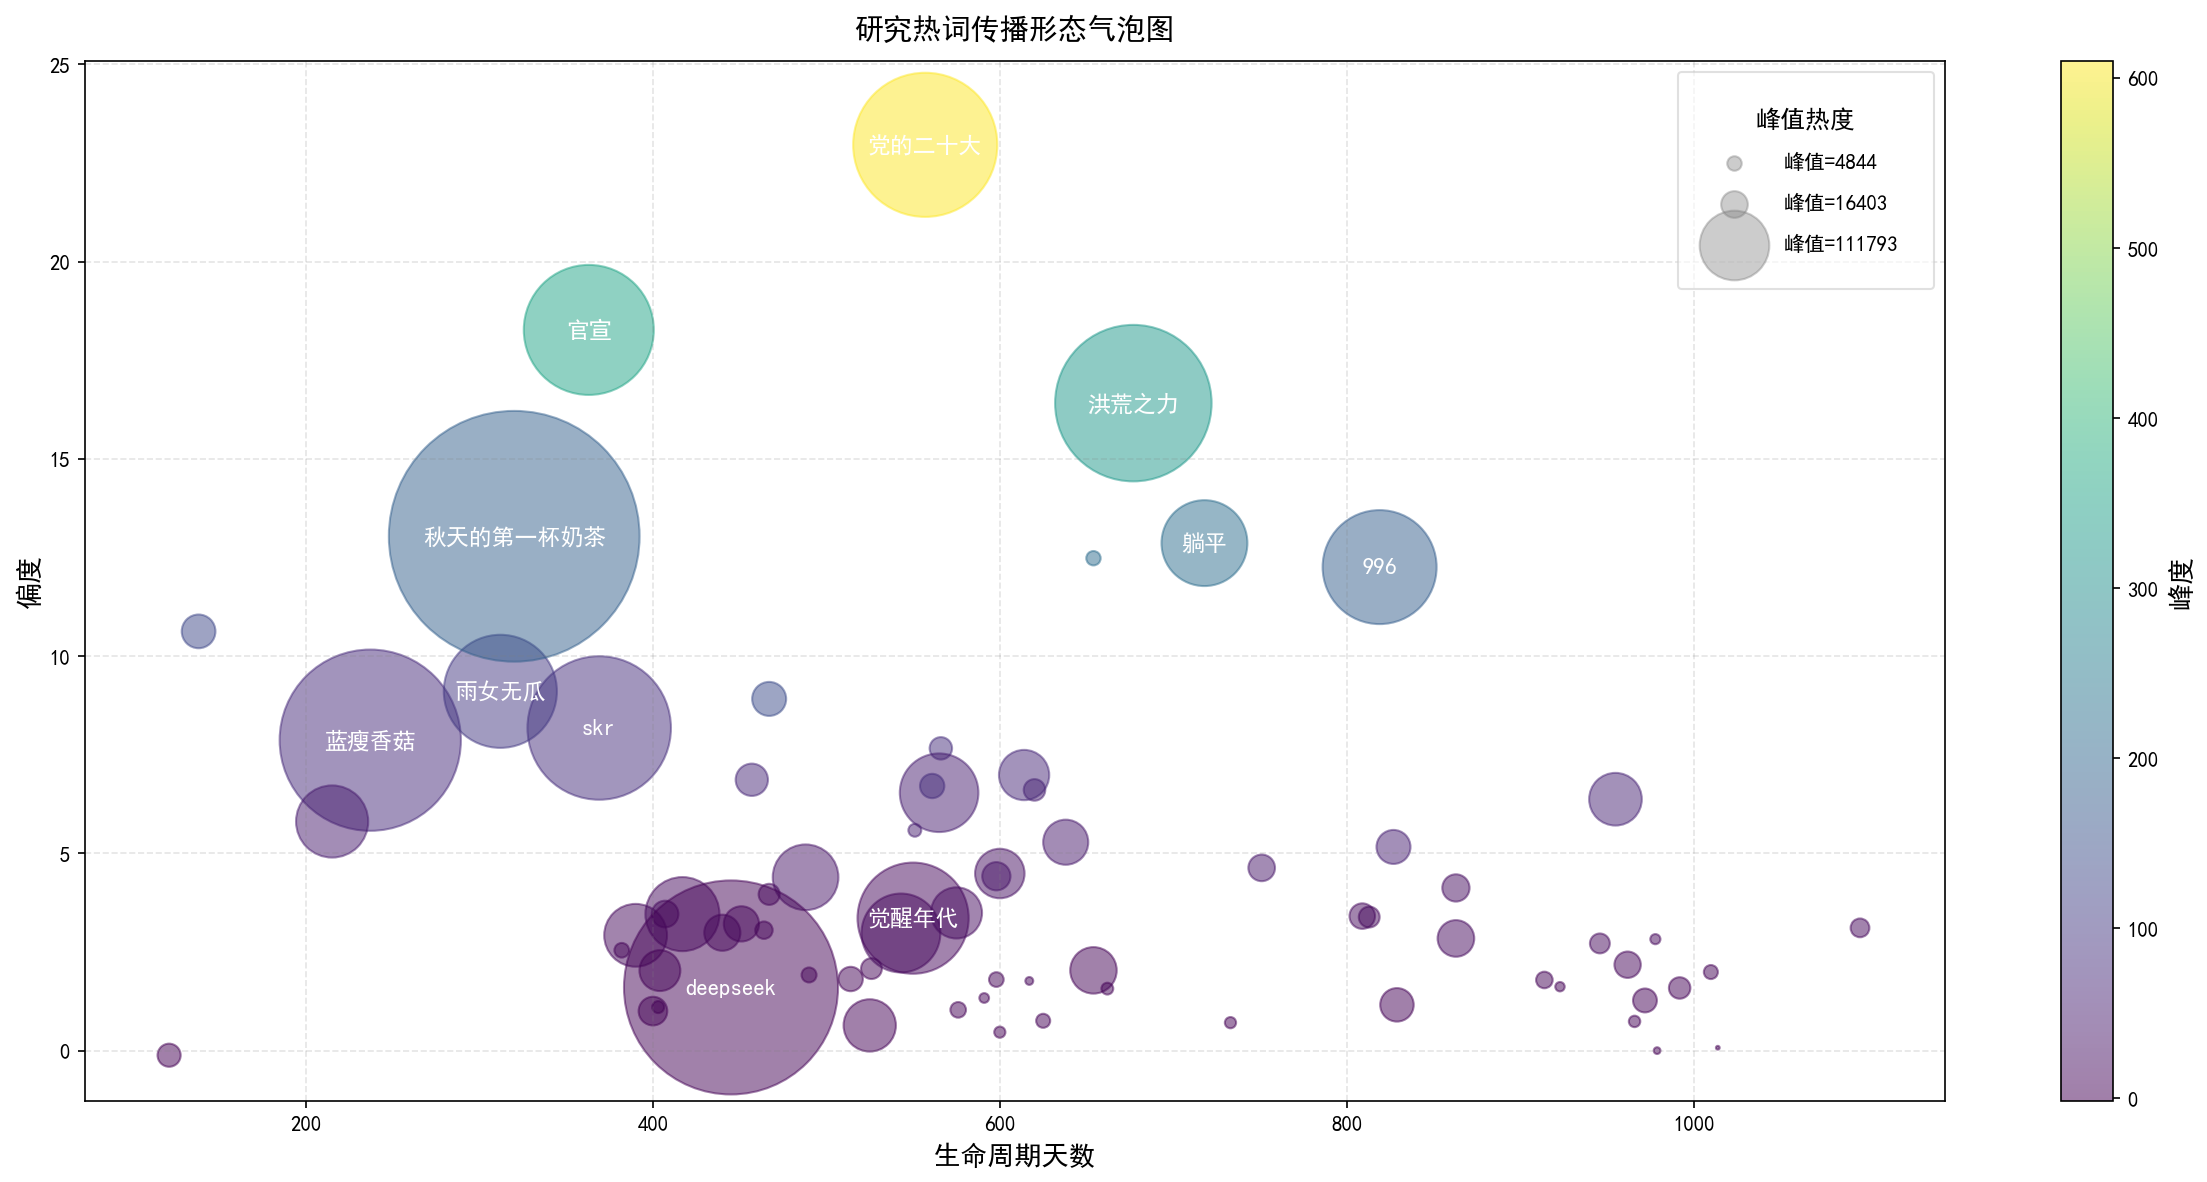

In [629]:
# 1)设置画布并进行气泡图绘制
# 注：气泡图绘制方法向AI请教而来，100作为经验系数用于自动压缩峰值超大值，viridis是AI提供的经典配色方案
plt.figure(figsize=(20,9),dpi=150)
bubble=plt.scatter(df_feature['lifecycle_days'],df_feature['skewness'], 
                 s=df_feature['peak']/100,c=df_feature['kurtosis'], 
                 alpha=0.5,cmap='viridis')

#因绘制出来最上面黄圈和下面紫圈都有被截断的，所以求助AI，用ylow,yhigh接收y轴坐标极值，并将上限扩大防止被阶段
ylow,yhigh=plt.ylim()
plt.ylim(ylow, yhigh*1.04)

#因为想要标注几个标签，询问AI，提供nlargest()和annotate()的使用方法，然后根据此图具体情况完成此部分代码
top11=df_feature.nlargest(11,'peak')
for i,row in top11.iterrows():
    plt.annotate(row['keyword'],xy=(row['lifecycle_days'],row['skewness']),
                 fontsize=11,color='white',ha='center',va='center')

#圆圈大小的图例设置
#注：此部分由AI生成，做了少数修改
ref_peak = np.array([df_feature['peak'].quantile(0.2),
                     df_feature['peak'].quantile(0.5),
                     df_feature['peak'].quantile(0.8)])
ref_size = ref_peak/100
handles = [plt.scatter([],[],s=sz,c='gray',alpha=0.4) for sz in ref_size]
labels = [f'峰值={int(v)}' for v in ref_peak]
plt.legend(handles,labels,title="峰值热度",loc="upper right",
           framealpha=0.6,borderpad=1.7,title_fontsize=12,handletextpad=1.4,labelspacing=1.05)


#进行其他图表信息设置
# 注：colorbar()画法询问AI
plt.colorbar(bubble).set_label('峰度',fontsize=13)
plt.title('研究热词传播形态气泡图',y=1.01,fontsize=14)
plt.xlabel('生命周期天数',fontsize=13)
plt.ylabel('偏度',fontsize=13)
plt.grid(alpha=0.2,linestyle='--',color='grey')
plt.savefig(r"d:\Users\谢\Desktop\本学期课程\主修\传播数据分析（python）\大作业\charts\研究热词传播形态气泡图.png",
            dpi=300,bbox_inches='tight',pad_inches=0.2)
plt.show()